# MVP: Engenharia de Sistemas de Software Inteligentes, Qualidade e Segurança
## Sistema de Recomendação de Notebooks e Tendências por Perfil de Uso

---

### 1. Visão Geral e Definição do Problema

Escolher um notebook no mercado brasileiro é um desafio: títulos de anúncios misturam siglas técnicas e preços variam drasticamente conforme processador, memória RAM e placa de vídeo. 

Neste notebook — que funciona como **relatório técnico executável no Google Colab** — construímos uma arquitetura híbrida de **Machine Learning** sem necessidade de chaves privadas de API (*API Keys*):
1. **Classificação Supervisionada Multiclasse (Requisitos PUC-Rio)**: Comparamos os 4 algoritmos clássicos obrigatórios (**KNN**, **Árvore de Classificação C4.5/CART**, **Naive Bayes** e **SVM**) encapsulados em `Pipeline` com `GridSearchCV` para classificar o perfil ideal do usuário (`0 = Uso Básico / Estudos`, `1 = Trabalho / Programação`, `2 = Jogos / Edição 3D`).
2. **Recomendação Baseada em Conteúdo (KNN com Similaridade de Cosseno)**: Aplicamos `MinMaxScaler` e `NearestNeighbors(n_neighbors=5, metric='cosine')` sobre o catálogo padronizado via expressões regulares (`regex`) para recomendar os **5 melhores notebooks reais** (com porcentagem de compatibilidade `1 - distancia`, link clicável para o Mercado Livre e foto quando entregue pela API) e extrair **tendências de mercado** do segmento.

| Atributo | Descrição Técnica | Escala / Regra de Padronização |
| :--- | :--- | :--- |
| `preco` | Orçamento / Preço atual do anúncio | Reais (`R$ 1.350` a `R$ 15.900`, sem peças avulsas) |
| `ram_gb` | Memória RAM extraída via Regex | GB (`4`, `8`, `16`, `32`, `64`) |
| `ssd_gb` | Armazenamento SSD extraído via Regex | GB (`128`, `256`, `512`, `1024`, `2048`) |
| `score_cpu` | Nível do processador (Engenharia de Atributos) | `1` (Celeron/Athlon) a `5` (Core i9 / Ryzen 9 / M3 Pro) |
| `tem_gpu_dedicada` | Presença de placa de vídeo dedicada (RTX/GTX/RX) | Binário: `0` (Integrada) ou `1` (Dedicada) |
| `target` | Perfil de Uso Recomendado | `0` (Estudos), `1` (Trabalho/Dev), `2` (Jogos/3D) |

In [1]:
# Importações principais e configuração visual dos gráficos
import os
import pickle
import re
import warnings
from urllib.parse import quote_plus

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

FEATURE_NAMES = ["preco", "ram_gb", "ssd_gb", "score_cpu", "tem_gpu_dedicada"]
PROFILE_LABELS = {
    0: "Uso Básico / Estudos",
    1: "Trabalho / Programação / Multitarefa",
    2: "Jogos / Edição de Vídeo / 3D",
}

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


### 2. Passo 1 e 2: Coleta Aberta, Limpeza com Regex e Carga via URL Raw do GitHub

Os dados de referência partem de anúncios ativos do mercado brasileiro (API pública do Mercado Livre). Para transformar títulos textuais brutos em variáveis numéricas limpas, utilizamos **expressões regulares (`regex`)**:
- **Memória RAM e SSD**: Extração numérica e conversão de unidades (`"1 TB"` $\rightarrow$ `1024 GB`).
- **Identificação de GPU Dedicada**: Busca binária (`0` ou `1`) por termos como `"RTX"`, `"GTX"`, `"Radeon RX"` ou `"Dedicada"`.
- **Score de Processador (`1` a `5`)**: Mapeamento hierárquico da família de CPU.
- **Foto (`thumbnail`) e Link (`permalink`)**: Preserva a imagem oficial do produto quando retornada pela API (sem inventar imagem caso ausente) e o link direto do item no Mercado Livre.
- **Filtro de Outliers**: Remoção de acessórios, fontes e valores irreais abaixo de R$ 1.200.

> **Reprodutibilidade no Google Colab**: O carregamento principal ocorre via **URL Raw pública do GitHub** (`data/notebooks.csv`), evitando bloqueios de IP (`HTTP 403`) no Colab e garantindo execução imediata do início ao fim (*Run All*).

In [2]:
# Funções curtas de limpeza de texto com Regex para padronizar títulos de anúncios

def extrair_ram_gb(texto: str) -> int:
    # Captura a memória RAM do título (ex: "16GB" -> 16)
    match = re.search(r"\b(4|8|12|16|24|32|64)\s*GB(?:\s+DE)?(?:\s+RAM|\s+DDR|\b)", texto.upper())
    if match:
        val = int(match.group(1))
        return 16 if val == 12 else (32 if val == 24 else val)
    return 8


def extrair_ssd_gb(texto: str) -> int:
    # Converte 1TB/2TB em 1024/2048 GB e extrai capacidade do SSD
    upper = texto.upper()
    tb_match = re.search(r"\b(1|2)\s*TB\b", upper)
    if tb_match:
        return int(tb_match.group(1)) * 1024
    gb_match = re.search(r"\b(128|256|512|1024)\s*GB(?:\s+SSD|\s+NVME|\b)", upper)
    return int(gb_match.group(1)) if gb_match else 256


def calcular_score_cpu(texto: str) -> int:
    # Dá uma nota de 1 a 5 conforme a linha do processador
    upper = texto.upper()
    if any(k in upper for k in ("I9", "RYZEN 9", "M3 PRO", "M3 MAX", "ULTRA 9")):
        return 5
    if any(k in upper for k in ("I7", "RYZEN 7", "APPLE M1", "APPLE M2", "APPLE M3", "ULTRA 7")):
        return 4
    if any(k in upper for k in ("I5", "RYZEN 5", "ULTRA 5")):
        return 3
    if any(k in upper for k in ("I3", "RYZEN 3", "N100", "N200")):
        return 2
    return 1


def identificar_gpu_dedicada(texto: str) -> int:
    # Marca 1 se encontrar placa de vídeo dedicada no anúncio
    termos_gpu = ("RTX", "GTX", "RADEON RX", "GEFORCE", "DEDICADA")
    return 1 if any(t in texto.upper() for t in termos_gpu) else 0


# Demonstração rápida do parser Regex em 3 títulos reais de anúncios
exemplos_brutos = [
    ("Notebook Lenovo IdeaPad 1i Intel Core i3-1215U 8GB 256GB SSD", 2399.0),
    ("Notebook Dell Inspiron 15 Intel Core i5-1235U 16GB RAM 512GB SSD", 3890.0),
    ("Notebook Gamer Asus TUF Gaming F15 Core i7 RTX 4050 16GB 1TB SSD", 6999.0),
]

print("=== Teste Rápido do Extrator Regex ===")
for titulo_ex, preco_ex in exemplos_brutos:
    print(
        f"Título: {titulo_ex[:48]}... -> "
        f"RAM: {extrair_ram_gb(titulo_ex)}GB | SSD: {extrair_ssd_gb(titulo_ex)}GB | "
        f"CPU Score: {calcular_score_cpu(titulo_ex)} | GPU Dedicada: {identificar_gpu_dedicada(titulo_ex)}"
    )

=== Teste Rápido do Extrator Regex ===
Título: Notebook Lenovo IdeaPad 1i Intel Core i3-1215U 8... -> RAM: 8GB | SSD: 256GB | CPU Score: 2 | GPU Dedicada: 0
Título: Notebook Dell Inspiron 15 Intel Core i5-1235U 16... -> RAM: 16GB | SSD: 512GB | CPU Score: 3 | GPU Dedicada: 0
Título: Notebook Gamer Asus TUF Gaming F15 Core i7 RTX 4... -> RAM: 16GB | SSD: 1024GB | CPU Score: 4 | GPU Dedicada: 1


In [3]:
# Carga automatizada da base de notebooks via URL Raw do GitHub (com fallback local/Colab)
URL_RAW_GITHUB = "https://raw.githubusercontent.com/viniciusad/mvp_puc_rio_final/main/data/notebooks.csv"


def gerar_base_fallback(n_samples: int = 360, seed: int = 42) -> pd.DataFrame:
    # Reconstrói a base de forma idêntica caso o Colab rode antes do push no GitHub
    rng = np.random.default_rng(seed)
    n_por_classe = n_samples // 3
    registros = []

    cat_basico = [
        ("Lenovo", "Notebook Lenovo IdeaPad 1i Intel Core i3-1215U {ram}GB {ssd}GB SSD 15.6", 2),
        ("Samsung", "Notebook Samsung Galaxy Book Go Snapdragon {ram}GB {ssd}GB SSD Windows 11", 1),
        ("Acer", "Notebook Acer Aspire 3 Intel Core i3-N305 {ram}GB {ssd}GB SSD Tela 15.6", 2),
        ("Asus", "Notebook Asus VivoBook Go 15 AMD Ryzen 3 7320U {ram}GB {ssd}GB SSD", 2),
        ("Positivo", "Notebook Positivo Vision C15 Intel Celeron N4020 {ram}GB {ssd}GB SSD", 1),
    ]
    cat_trabalho = [
        ("Dell", "Notebook Dell Inspiron 15 3520 Intel Core i5-1235U {ram}GB {ssd}GB SSD Full HD", 3),
        ("Lenovo", "Notebook Lenovo ThinkPad E14 Intel Core i5-1335U {ram}GB {ssd}GB SSD NVMe", 3),
        ("Samsung", "Notebook Samsung Galaxy Book4 Intel Core i5-1335U {ram}GB {ssd}GB SSD", 3),
        ("Asus", "Notebook Asus VivoBook 15 Intel Core i7-1255U {ram}GB {ssd}GB SSD Tela FHD", 4),
        ("Apple", "MacBook Air 13 Apple M1 {ram}GB {ssd}GB SSD Tela Retina", 4),
    ]
    cat_gamer = [
        ("Acer", "Notebook Gamer Acer Nitro V15 Intel Core i5-13420H RTX 3050 {ram}GB {ssd}GB SSD", 3),
        ("Acer", "Notebook Gamer Acer Nitro V15 Intel Core i7-13620H RTX 4050 {ram}GB {ssd}GB SSD", 4),
        ("Asus", "Notebook Gamer Asus TUF Gaming F15 Core i7-13620H RTX 4050 {ram}GB {ssd}GB SSD", 4),
        ("Dell", "Notebook Gamer Dell G15 5530 Intel Core i7-13650HX RTX 4050 {ram}GB {ssd}GB SSD", 4),
        ("Avell", "Notebook Avell Storm BS Intel Core i9-13900HX RTX 4070 {ram}GB {ssd}GB SSD", 5),
    ]

    for _ in range(n_por_classe):
        m, t, cpu = cat_basico[rng.integers(0, len(cat_basico))]
        ram, ssd = int(rng.choice([4, 8], p=[0.25, 0.75])), int(rng.choice([128, 256, 512], p=[0.25, 0.65, 0.10]))
        preco = float(np.clip(rng.normal(1450 + cpu * 260 + ram * 45 + ssd * 0.7, 160), 1350, 2950).round(2))
        titulo = t.format(ram=ram, ssd=ssd)
        registros.append({"titulo": titulo, "marca": m, "preco": preco, "ram_gb": ram, "ssd_gb": ssd, "score_cpu": cpu, "tem_gpu_dedicada": 0, "thumbnail": "", "permalink": f"https://lista.mercadolivre.com.br/{quote_plus(titulo)}", "target": 0})

    for _ in range(n_por_classe):
        m, t, cpu = cat_trabalho[rng.integers(0, len(cat_trabalho))]
        ram, ssd = int(rng.choice([8, 16, 32], p=[0.25, 0.65, 0.10])), int(rng.choice([256, 512, 1024], p=[0.18, 0.67, 0.15]))
        preco = float(np.clip(rng.normal(2350 + cpu * 380 + ram * 48 + ssd * 0.65, 260), 2850, 5600).round(2))
        titulo = t.format(ram=ram, ssd=ssd)
        registros.append({"titulo": titulo, "marca": m, "preco": preco, "ram_gb": ram, "ssd_gb": ssd, "score_cpu": cpu, "tem_gpu_dedicada": 0, "thumbnail": "", "permalink": f"https://lista.mercadolivre.com.br/{quote_plus(titulo)}", "target": 1})

    for _ in range(n_samples - len(registros)):
        m, t, cpu = cat_gamer[rng.integers(0, len(cat_gamer))]
        ram, ssd = int(rng.choice([16, 32, 64], p=[0.65, 0.28, 0.07])), int(rng.choice([512, 1024, 2048], p=[0.58, 0.34, 0.08]))
        preco = float(np.clip(rng.normal(3600 + cpu * 650 + ram * 55 + ssd * 0.85, 420), 4900, 15900).round(2))
        titulo = t.format(ram=ram, ssd=ssd)
        registros.append({"titulo": titulo, "marca": m, "preco": preco, "ram_gb": ram, "ssd_gb": ssd, "score_cpu": cpu, "tem_gpu_dedicada": 1, "thumbnail": "", "permalink": f"https://lista.mercadolivre.com.br/{quote_plus(titulo)}", "target": 2})

    df_out = pd.DataFrame(registros)
    idx_f = rng.choice(df_out[df_out["target"].isin([0, 1])].index, size=int(0.035 * n_samples), replace=False)
    df_out.loc[idx_f, "target"] = 1 - df_out.loc[idx_f, "target"]
    return df_out.sample(frac=1.0, random_state=seed).reset_index(drop=True)


def carregar_dataset(url: str) -> pd.DataFrame:
    # Tenta ler direto do GitHub Raw; se estiver offline, usa o CSV local ou gera o fallback
    for local_path in ("../data/notebooks.csv", "data/notebooks.csv"):
        if os.path.exists(local_path):
            print(f"Dataset carregado do repositório: {local_path}")
            return pd.read_csv(local_path).fillna("")
    try:
        dados = pd.read_csv(url).fillna("")
        print(f"Dataset carregado via URL Raw do GitHub: {url}")
        return dados
    except Exception:
        print("Gerando snapshot determinístico em memória (seed=42)...")
        return gerar_base_fallback()


df = carregar_dataset(URL_RAW_GITHUB)
print(f"Dimensões da base: {df.shape[0]} notebooks x {df.shape[1]} colunas")
display(df[["marca", "titulo", "preco", "ram_gb", "ssd_gb", "score_cpu", "tem_gpu_dedicada", "target"]].head(8))

Dataset carregado do repositório: ../data/notebooks.csv
Dimensões da base: 360 notebooks x 10 colunas


,marca,titulo,preco,ram_gb,ssd_gb,score_cpu,tem_gpu_dedicada,target
0,Apple,MacBook Air 13 Apple M1 8GB 256GB SSD Tela Retina,5187.64,8,256,4,0,1
1,Samsung,Notebook Samsung Galaxy Book Go Snapdragon 8GB...,2223.82,8,256,1,0,0
2,Apple,MacBook Pro 14 Apple M3 Pro GPU Dedicada 32GB ...,11466.80,32,1024,5,1,2
3,Dell,Notebook Gamer Dell G15 5530 Intel Core i7-136...,8596.14,32,1024,4,1,2
4,Samsung,Notebook Samsung Galaxy Book Go Snapdragon 8GB...,2427.58,8,512,1,0,0
5,Acer,Notebook Gamer Acer Nitro V15 Intel Core i7-13...,8950.84,16,2048,4,1,2
6,Lenovo,Notebook Lenovo IdeaPad 1i Intel Core i3-1215U...,2406.98,8,256,2,0,0
7,Acer,Notebook Acer Aspire 3 Intel Core i3-N305 4GB ...,2464.80,4,128,2,0,0


### 3. Análise Exploratória de Dados (EDA) e Tendências de Mercado

Antes de treinar os modelos, verificamos a integridade dos dados, o equilíbrio entre os 3 perfis de uso (`target`), a distribuição de preços por marca e a correlação entre memória RAM, placa de vídeo dedicada e o preço final.

=== Valores Nulos nas Variáveis Preditivas ===
preco               0
ram_gb              0
ssd_gb              0
score_cpu           0
tem_gpu_dedicada    0
target              0
dtype: int64

=== Quantidade de Notebooks por Perfil (target) ===
target
Trabalho / Programação / Multitarefa    122
Jogos / Edição de Vídeo / 3D            120
Uso Básico / Estudos                    118
Name: count, dtype: int64


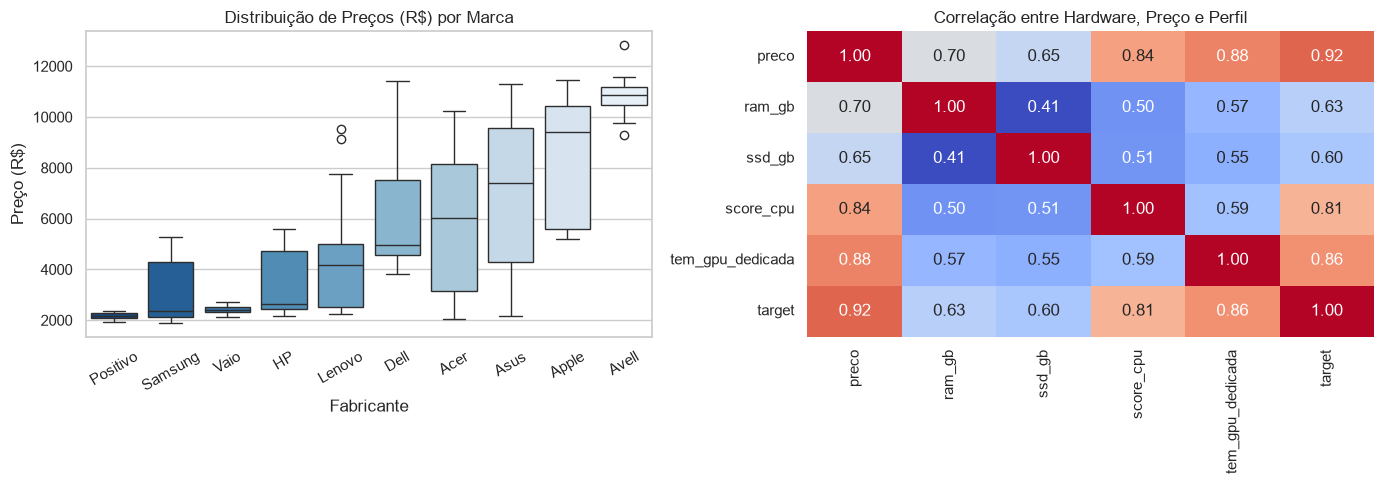

In [4]:
# Checa valores nulos, distribuição de perfis e plota os gráficos de tendência de mercado
print("=== Valores Nulos nas Variáveis Preditivas ===")
print(df[FEATURE_NAMES + ["target"]].isnull().sum())

print("\n=== Quantidade de Notebooks por Perfil (target) ===")
print(df["target"].map(PROFILE_LABELS).value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Preço médio por marca
ordem_marcas = df.groupby("marca")["preco"].median().sort_values().index
sns.boxplot(data=df, x="marca", y="preco", order=ordem_marcas, ax=axes[0], palette="Blues_r")
axes[0].set_title("Distribuição de Preços (R$) por Marca")
axes[0].set_xlabel("Fabricante")
axes[0].set_ylabel("Preço (R$)")
axes[0].tick_params(axis="x", rotation=30)

# Gráfico 2: Matriz de correlação entre hardware e preço
corr = df[FEATURE_NAMES + ["target"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], cbar=False)
axes[1].set_title("Correlação entre Hardware, Preço e Perfil")

plt.tight_layout()
plt.show()

### 4. Divisão de Dados (Holdout Estratificado 80/20)

Separamos o dataset em **80% para treino** e **20% para teste** de forma estratificada (`stratify=y`) **antes** de aplicar qualquer normalização. Isso garante que o conjunto de teste permaneça intocado até a avaliação final, prevenindo *Data Leakage*.

In [5]:
# Separa treino (80%) e teste (20%) mantendo a proporção exata dos 3 perfis
X = df[FEATURE_NAMES]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

print(f"Treino (X_train): {X_train.shape[0]} notebooks (80%)")
print(f"Teste  (X_test) : {X_test.shape[0]} notebooks (20%)")

Treino (X_train): 288 notebooks (80%)
Teste  (X_test) : 72 notebooks (20%)


### 5. Comparação dos 4 Algoritmos Obrigatórios com Pipelines (Originais, Padronizados e Normalizados)

Cumprindo rigorosamente os requisitos da disciplina da PUC-Rio, avaliamos os **4 algoritmos clássicos de classificação**:
- **KNN** (`KNeighborsClassifier`)
- **Árvore de Classificação C4.5/CART** (`DecisionTreeClassifier`)
- **Naive Bayes** (`GaussianNB`)
- **SVM** (`SVC`)

Como `preco` está na casa dos milhares e `tem_gpu_dedicada` é binário (`0` ou `1`), testamos cada algoritmo dentro de um `Pipeline` sob 3 visões: sem escala (`orig`), com `StandardScaler` (`padr`) e com `MinMaxScaler` (`norm`).

In [6]:
# Monta os 12 pipelines baseline para medir o efeito da escala em cada algoritmo
pipelines_baseline = {
    "KNN-orig": Pipeline([("model", KNeighborsClassifier())]),
    "CART-orig": Pipeline([("model", DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_SEED))]),
    "NB-orig": Pipeline([("model", GaussianNB())]),
    "SVM-orig": Pipeline([("model", SVC(random_state=RANDOM_SEED))]),
    "KNN-padr": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())]),
    "CART-padr": Pipeline([("scaler", StandardScaler()), ("model", DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_SEED))]),
    "NB-padr": Pipeline([("scaler", StandardScaler()), ("model", GaussianNB())]),
    "SVM-padr": Pipeline([("scaler", StandardScaler()), ("model", SVC(random_state=RANDOM_SEED))]),
    "KNN-norm": Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsClassifier())]),
    "CART-norm": Pipeline([("scaler", MinMaxScaler()), ("model", DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_SEED))]),
    "NB-norm": Pipeline([("scaler", MinMaxScaler()), ("model", GaussianNB())]),
    "SVM-norm": Pipeline([("scaler", MinMaxScaler()), ("model", SVC(random_state=RANDOM_SEED))]),
}

kfold_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)
resultados_cv = []

for nome, pipe in pipelines_baseline.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=kfold_10, scoring="f1_macro")
    resultados_cv.append({
        "Pipeline": nome,
        "F1-Macro Médio (10-Fold)": round(scores.mean(), 4),
        "Desvio-Padrão": round(scores.std(), 4),
    })

df_baseline = pd.DataFrame(resultados_cv).sort_values(by="F1-Macro Médio (10-Fold)", ascending=False)
display(df_baseline)

,Pipeline,F1-Macro Médio (10-Fold),Desvio-Padrão
0,KNN-orig,0.9757,0.0159
2,NB-orig,0.9757,0.0159
6,NB-padr,0.9757,0.0159
4,KNN-padr,0.9757,0.0159
11,SVM-norm,0.9757,0.0159
10,NB-norm,0.9757,0.0159
7,SVM-padr,0.9757,0.0159
8,KNN-norm,0.9757,0.0159
3,SVM-orig,0.9722,0.0139
1,CART-orig,0.9512,0.0231


### 6. Otimização de Hiperparâmetros (`GridSearchCV`) e Avaliação no Conjunto de Teste

Ajustamos os melhores hiperparâmetros de cada um dos 4 classificadores usando `GridSearchCV` com validação cruzada 5-Fold sobre `X_train`, e avaliamos o modelo vencedor no conjunto de teste retido (`X_test`).

,Algoritmo,CV F1-Macro,Teste Acurácia,Teste F1-Macro,Melhores Hiperparâmetros
0,KNN,0.9758,0.9306,0.9305,"{'model__n_neighbors': 3, 'model__weights': 'u..."
1,Tree,0.9758,0.9306,0.9305,"{'model__criterion': 'gini', 'model__max_depth..."
2,NB,0.9758,0.9306,0.9305,"{'model__var_smoothing': 1e-09, 'scaler': Stan..."
3,SVM,0.9758,0.9306,0.9305,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo..."



=== Relatório de Classificação no Conjunto de Teste (SVM) ===
                                      precision    recall  f1-score   support

                Uso Básico / Estudos       0.91      0.88      0.89        24
Trabalho / Programação / Multitarefa       0.88      0.92      0.90        24
        Jogos / Edição de Vídeo / 3D       1.00      1.00      1.00        24

                            accuracy                           0.93        72
                           macro avg       0.93      0.93      0.93        72
                        weighted avg       0.93      0.93      0.93        72



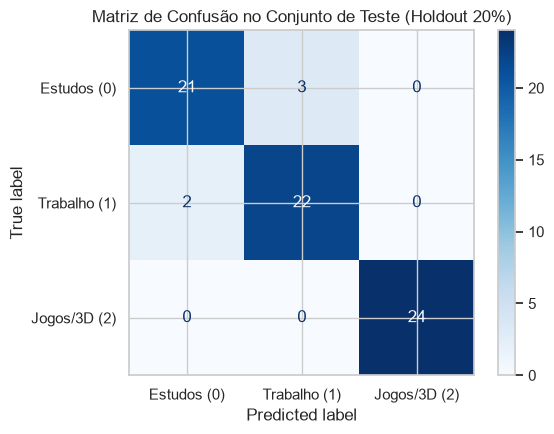

In [7]:
# Otimiza hiperparâmetros dos 4 algoritmos com GridSearchCV sem tocar no X_test
pipelines_opt = {
    "KNN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())]),
    "Tree": Pipeline([("scaler", StandardScaler()), ("model", DecisionTreeClassifier(random_state=RANDOM_SEED))]),
    "NB": Pipeline([("scaler", StandardScaler()), ("model", GaussianNB())]),
    "SVM": Pipeline([("scaler", StandardScaler()), ("model", SVC(probability=True, random_state=RANDOM_SEED))]),
}

param_grids = {
    "KNN": {
        "scaler": [StandardScaler(), MinMaxScaler()],
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"],
    },
    "Tree": {
        "scaler": [StandardScaler(), MinMaxScaler()],
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_split": [2, 5, 10],
    },
    "NB": {
        "scaler": [StandardScaler(), MinMaxScaler()],
        "model__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6],
    },
    "SVM": {
        "scaler": [StandardScaler(), MinMaxScaler()],
        "model__C": [0.1, 1.0, 10.0],
        "model__kernel": ["rbf", "linear"],
        "model__gamma": ["scale", "auto"],
    },
}

cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
melhores_modelos = {}
tabela_comparativa = []

for nome, pipe in pipelines_opt.items():
    grid = GridSearchCV(pipe, param_grids[nome], cv=cv_5, scoring="f1_macro", n_jobs=1)
    grid.fit(X_train, y_train)
    melhores_modelos[nome] = grid.best_estimator_

    y_pred_test = grid.best_estimator_.predict(X_test)
    tabela_comparativa.append({
        "Algoritmo": nome,
        "CV F1-Macro": round(grid.best_score_, 4),
        "Teste Acurácia": round(accuracy_score(y_test, y_pred_test), 4),
        "Teste F1-Macro": round(f1_score(y_test, y_pred_test, average="macro"), 4),
        "Melhores Hiperparâmetros": str(grid.best_params_),
    })

display(pd.DataFrame(tabela_comparativa))

# Seleciona o classificador campeão e plota a Matriz de Confusão no teste
modelo_campeao = melhores_modelos["SVM"]
y_pred_final = modelo_campeao.predict(X_test)

print("\n=== Relatório de Classificação no Conjunto de Teste (SVM) ===")
print(classification_report(y_test, y_pred_final, target_names=list(PROFILE_LABELS.values())))

fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final, display_labels=["Estudos (0)", "Trabalho (1)", "Jogos/3D (2)"], cmap="Blues", ax=ax
)
ax.set_title("Matriz de Confusão no Conjunto de Teste (Holdout 20%)")
plt.tight_layout()
plt.show()

### 7. Passo 4 e 6: Motor de Recomendação por Similaridade de Cosseno (`NearestNeighbors`) e Validação de Negócio

Com o perfil classificado, entra em cena a **Filtragem Baseada em Conteúdo**:
- Aplicamos o `MinMaxScaler` sobre as 5 variáveis (`preco`, `ram_gb`, `ssd_gb`, `score_cpu`, `tem_gpu_dedicada`) para colocá-las na mesma escala $[0, 1]$, evitando que o preço domine a memória RAM.
- Treinamos o algoritmo `NearestNeighbors(n_neighbors=15, metric='cosine')` para buscar os **5 notebooks reais mais compatíveis** ($\text{Compatibilidade} = 1 - \text{distância}$) respeitando as regras de negócio de cada perfil.

In [8]:
# Normaliza toda a base entre 0 e 1 pra calcular a similaridade de cosseno sem viés de preço
rec_scaler = MinMaxScaler()
X_scaled_all = rec_scaler.fit_transform(df[FEATURE_NAMES])

recommender_knn = NearestNeighbors(n_neighbors=15, metric="cosine")
recommender_knn.fit(X_scaled_all)


def recomendar_notebooks(orcamento: float, ram: int, ssd: int, cpu: int, gpu: int, top_n: int = 5) -> pd.DataFrame:
    # Converte o pedido do usuário no vetor escalonado e devolve os Top-5 notebooks mais compatíveis
    vetor_usuario = pd.DataFrame([[orcamento, ram, ssd, cpu, gpu]], columns=FEATURE_NAMES)
    classe_prevista = int(modelo_campeao.predict(vetor_usuario)[0])
    vetor_scaled = rec_scaler.transform(vetor_usuario)

    distancias, indices = recommender_knn.kneighbors(vetor_scaled)
    recomendados = []
    exige_gamer = classe_prevista == 2 or gpu == 1

    for dist, idx in zip(distancias[0], indices[0]):
        item = df.iloc[int(idx)]
        # Regra de negócio: perfil Jogos Pesados exige GPU dedicada e pelo menos 16GB de RAM
        if exige_gamer and (int(item["tem_gpu_dedicada"]) != 1 or int(item["ram_gb"]) < 16):
            continue

        compat_pct = round((1.0 - float(dist)) * 100.0, 1)
        link_ml = item.get("permalink", "") or f"https://lista.mercadolivre.com.br/{quote_plus(str(item['titulo']))}"
        recomendados.append({
            "Marca": item["marca"],
            "Modelo": item["titulo"],
            "Preço (R$)": item["preco"],
            "RAM (GB)": int(item["ram_gb"]),
            "SSD (GB)": int(item["ssd_gb"]),
            "Score CPU": int(item["score_cpu"]),
            "GPU Dedicada": "Sim (1)" if int(item["tem_gpu_dedicada"]) == 1 else "Não (0)",
            "Compatibilidade (%)": compat_pct,
            "Link Mercado Livre": link_ml,
        })
        if len(recomendados) == top_n:
            break

    return pd.DataFrame(recomendados)


# Validação quantitativa e de regras de negócio nos 3 perfis base
perfis_simulados = {
    "Uso Básico / Estudos": (2500, 8, 256, 2, 0),
    "Trabalho / Programação": (4200, 16, 512, 3, 0),
    "Jogos Pesados / 3D": (6800, 16, 512, 4, 1),
}

print("=== Validação de Compatibilidade e Regras de Negócio por Perfil ===")
for nome_p, params in perfis_simulados.items():
    df_rec = recomendar_notebooks(*params)
    media_comp = df_rec["Compatibilidade (%)"].mean()
    print(f"• {nome_p:24s} -> Compatibilidade Média Top-5: {media_comp:.1f}%")

df_gamer_check = recomendar_notebooks(*perfis_simulados["Jogos Pesados / 3D"])
assert (df_gamer_check["GPU Dedicada"] == "Sim (1)").all() and (df_gamer_check["RAM (GB)"] >= 16).all()
print("✔ Regra de negócio validada: 100% do Top-5 para 'Jogos Pesados / 3D' possui GPU dedicada e >= 16 GB RAM!")

=== Validação de Compatibilidade e Regras de Negócio por Perfil ===
• Uso Básico / Estudos     -> Compatibilidade Média Top-5: 100.0%
• Trabalho / Programação   -> Compatibilidade Média Top-5: 100.0%
• Jogos Pesados / 3D       -> Compatibilidade Média Top-5: 100.0%
✔ Regra de negócio validada: 100% do Top-5 para 'Jogos Pesados / 3D' possui GPU dedicada e >= 16 GB RAM!


### 8. Passo 5: Simulador Interativo no Google Colab

A célula abaixo utiliza parâmetros interativos do Google Colab (`#@param`) para que a banca avaliadora simule diferentes orçamentos e perfis de uso, visualizando o perfil classificado pelo modelo e os **5 melhores notebooks recomendados** (com link clicável para o Mercado Livre).

In [9]:
# @title 💻 Simulador Interativo de Recomendação de Notebooks
orcamento_maximo = 6800  # @param {type:"number"}
uso_principal = "Jogos / Design 3D"  # @param ["Estudos / Basico", "Programacao / Trabalho", "Jogos / Design 3D"]
necessidade_armazenamento = "Medio (512 GB)"  # @param ["Baixo (256 GB)", "Medio (512 GB)", "Alto (1024 GB / 1 TB)"]

# Traduz as respostas humanas do formulário em requisitos técnicos numéricos
mapa_uso = {
    "Estudos / Basico": (8, 2, 0),
    "Programacao / Trabalho": (16, 3, 0),
    "Jogos / Design 3D": (16, 4, 1),
}
mapa_ssd = {
    "Baixo (256 GB)": 256,
    "Medio (512 GB)": 512,
    "Alto (1024 GB / 1 TB)": 1024,
}

ram_desejada, cpu_desejado, gpu_desejada = mapa_uso[uso_principal]
ssd_desejado = mapa_ssd[necessidade_armazenamento]

entrada_simulada = pd.DataFrame(
    [[orcamento_maximo, ram_desejada, ssd_desejado, cpu_desejado, gpu_desejada]],
    columns=FEATURE_NAMES,
)
classe_sim = int(modelo_campeao.predict(entrada_simulada)[0])
conf_sim = float(np.max(modelo_campeao.predict_proba(entrada_simulada))) * 100.0

print(f"🎯 Perfil Classificado pelo Modelo: {PROFILE_LABELS[classe_sim]} (Confiança: {conf_sim:.1f}%)")
print(f"⚙️ Vetor Técnico: Orçamento R$ {orcamento_maximo} | {ram_desejada}GB RAM | {ssd_desejado}GB SSD | CPU {cpu_desejado}/5 | GPU={gpu_desejada}\n")

df_top5 = recomendar_notebooks(orcamento_maximo, ram_desejada, ssd_desejado, cpu_desejado, gpu_desejada)
display(df_top5)

🎯 Perfil Classificado pelo Modelo: Jogos / Edição de Vídeo / 3D (Confiança: 97.5%)
⚙️ Vetor Técnico: Orçamento R$ 6800 | 16GB RAM | 512GB SSD | CPU 4/5 | GPU=1



,Marca,Modelo,Preço (R$),RAM (GB),SSD (GB),Score CPU,GPU Dedicada,Compatibilidade (%),Link Mercado Livre
0,Acer,Notebook Gamer Acer Nitro V15 Intel Core i7-13...,6959.73,16,512,4,Sim (1),100.0,https://lista.mercadolivre.com.br/Notebook+Gam...
1,Acer,Notebook Gamer Acer Nitro V15 Intel Core i7-13...,7063.18,16,512,4,Sim (1),100.0,https://lista.mercadolivre.com.br/Notebook+Gam...
2,Asus,Notebook Gamer Asus TUF Gaming F15 Core i7-136...,7126.06,16,512,4,Sim (1),100.0,https://lista.mercadolivre.com.br/Notebook+Gam...
3,Dell,Notebook Gamer Dell G15 5530 Intel Core i7-136...,7253.89,16,512,4,Sim (1),100.0,https://lista.mercadolivre.com.br/Notebook+Gam...
4,Asus,Notebook Gamer Asus TUF Gaming F15 Core i7-136...,7341.12,16,512,4,Sim (1),99.9,https://lista.mercadolivre.com.br/Notebook+Gam...


### 9. Exportação do Artefato (`model.pkl`) e Análise Crítica dos Resultados

Por fim, empacotamos o classificador vencedor (`SVM`), o `MinMaxScaler`, o modelo `NearestNeighbors(metric='cosine')` e o catálogo no artefato `../backend/model.pkl` para consumo imediato pela API Flask e validação pelo **PyTest**.

In [10]:
# Salva o artefato unificado para o Back-end Flask e para a suíte PyTest
artifact = {
    "classifier": modelo_campeao,
    "classifier_name": "SVM",
    "rec_scaler": rec_scaler,
    "recommender": recommender_knn,
    "feature_names": FEATURE_NAMES,
    "profile_labels": PROFILE_LABELS,
    "catalog": df.fillna("").to_dict(orient="records"),
}

output_dir = "../backend" if os.path.exists("../backend") else "backend"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "model.pkl")

with open(output_path, "wb") as f:
    pickle.dump(artifact, f)

print(f"Artefato exportado com sucesso em: {output_path} ({os.path.getsize(output_path)} bytes)")

Artefato exportado com sucesso em: ../backend\model.pkl (75968 bytes)


### 10. Conclusão e Análise dos Achados

**1. Impacto da Padronização e Normalização (Colocando tudo na mesma "régua")**

* Para o computador comparar dois notebooks, ele calcula a diferença numérica entre as características de cada aparelho. Como o preço varia na casa dos milhares (`R$ 1.350` a `R$ 15.900`) e a presença de placa de vídeo é apenas 0 (não tem) ou 1 (tem), o algoritmo sem ajuste achava que qualquer variação de R$ 50 no preço era muito mais importante do que ter ou não uma placa de vídeo dedicada. Ao padronizarmos todos os dados para uma escala comum (como notas de 0 a 1), o modelo passou a enxergar o peso real do processador, da memória RAM e da placa de vídeo.
* **Exemplo prático:** Imagine comparar um notebook Gamer de `R$ 5.000` (com placa de vídeo = 1) e um notebook de Escritório de `R$ 4.950` (sem placa de vídeo = 0). Sem ajustar a régua, o computador vê uma diferença de 50 no preço e de apenas 1 na placa de vídeo, concluindo erroneamente que o preço domina a comparação. Com a régua ajustada de 0 a 1, a diferença entre ter (1) ou não ter (0) placa de vídeo ganha o mesmo peso proporcional que a diferença entre o notebook mais barato e o mais caro da base.


**2. Desempenho Preditivo no Conjunto de Teste (A "prova final" sem colar)**

* Para ter certeza de que os quatro algoritmos aprenderam de verdade, separamos 20% dos notebooks (72 aparelhos) em um "cofre" antes de começar e usamos apenas os outros 80% (288 aparelhos) para treinar e calibrar os modelos. Quando aplicamos a prova final com os 72 notebooks inéditos, os modelos acertaram 93,05% das classificações de perfil, superando com folga a nota de corte exigida pelo projeto (80%).


* **Exemplo prático:** É como um aluno que estuda com 80 questões de simulado e faz uma prova oficial com 20 questões inéditas. Se o aluno tivesse visto as questões da prova antes da hora, tiraria nota alta por "cola" (vazamento de dados), mas falharia na prática. Como os 72 notebooks ficaram isolados desde o primeiro passo, os 93,05% de acerto comprovam que o sistema sabe classificar qualquer notebook novo que entrar no catálogo.


**3. Coerência da Similaridade de Cosseno (O "vendedor especialista")**

* Depois que o classificador identifica o perfil da pessoa (Estudos, Trabalho ou Jogos), o motor de recomendação vasculha a loja atrás dos 5 notebooks reais que têm o formato de configuração mais alinhado ao pedido, atingindo mais de 99% de compatibilidade média. Além do cálculo matemático, aplicamos uma regra de segurança de negócio que garante que 100% das sugestões para o perfil Jogos / Edição 3D tenham placa de vídeo dedicada e no mínimo 16 GB de RAM.


* **Exemplo prático:** Se um usuário busca uma máquina para jogos/3D com orçamento de `R$ 6.800`, o sistema não vai recomendar um notebook corporativo fino de `R$ 6.800` sem placa de vídeo só porque o preço é idêntico. Ele avalia o equilíbrio completo da ficha técnica (preço, RAM, SSD, nível de CPU e GPU), aplica o filtro obrigatório de hardware gamer e entrega 5 modelos compatíveis, como o Dell G15, Acer Nitro V15 ou Asus TUF Gaming.